### 1- Batch Gradient Descent(vanilla GD)

Initial Loss: 48.6
Learned Weight: 1.4818
Final Loss: 0.2927


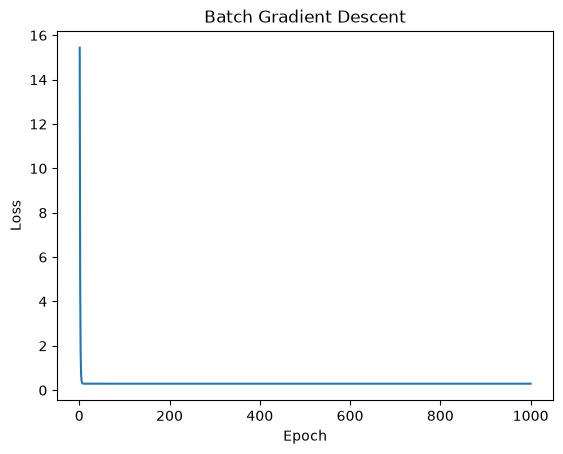

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset: study hours and marks
X = np.array([2, 4, 6, 8, 10]).reshape(-1, 1)
y = np.array([4, 7, 9, 12, 14])

# Initialize weight
W = np.zeros(1)

alpha = 0.01
epochs = 1000

# Calculate loss
def compute_loss(X, y, W):
    m = len(y)
    predictions = X.dot(W)
    return (1 / (2 * m)) * np.sum((predictions - y) ** 2)

# Batch Gradient Descent
def batch_gradient_descent(X, y, W, alpha, epochs):
    m = len(y)
    loss_history = []

    for epoch in range(epochs):
        predictions = X.dot(W)
        errors = predictions - y

        # Calculate gradient using the entire dataset
        gradient = (1 / m) * X.T.dot(errors)

        # Update weight
        W = W - alpha * gradient

        loss_history.append(compute_loss(X, y, W))

    return W, loss_history

initial_loss = compute_loss(X, y, W)

W, loss_history = batch_gradient_descent(
    X, y, W, alpha, epochs
)

print("Initial Loss:", round(initial_loss, 4))
print("Learned Weight:", round(W[0], 4))
print("Final Loss:", round(loss_history[-1], 4))

# Plot the loss
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Batch Gradient Descent")
plt.show()

### 2- Gradient Descent  with bias trick

Learned Bias: 1.4485
Learned Weight: 1.2844
Final Loss: 0.0358


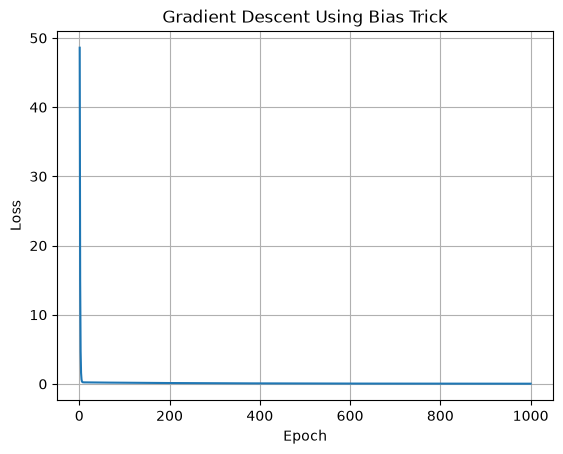

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset
X = np.array([2, 4, 6, 8, 10]).reshape(-1, 1)
y = np.array([4, 7, 9, 12, 14])

# Bias trick: add a column of ones
X_b = np.c_[np.ones((len(X), 1)), X]

# Initialize parameters: bias and weight
theta = np.zeros(2)

alpha = 0.01
epochs = 1000
m = len(y)

loss_history = []

for epoch in range(epochs):
    predictions = X_b.dot(theta)
    errors = predictions - y

    gradient = (1 / m) * X_b.T.dot(errors)
    theta = theta - alpha * gradient

    loss = (1 / (2 * m)) * np.sum(errors ** 2)
    loss_history.append(loss)

print("Learned Bias:", round(theta[0], 4))
print("Learned Weight:", round(theta[1], 4))
print("Final Loss:", round(loss_history[-1], 4))



plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Gradient Descent Using Bias Trick")
plt.grid(True)
plt.show()

### 3- Mini- Batch Gradient Descent

Learned Bias: 0.548
Learned Weight: 1.4089
Final Loss: 0.1507


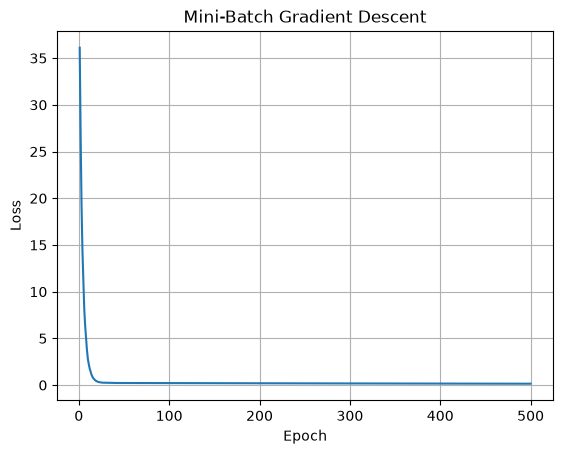

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset
X = np.array([2, 4, 6, 8, 10]).reshape(-1, 1)
y = np.array([4, 7, 9, 12, 14])

# Add bias column
X_b = np.c_[np.ones((len(X), 1)), X]

theta = np.zeros(2)
alpha = 0.001
epochs = 500
batch_size = 2
m = len(y)

loss_history = []

for epoch in range(epochs):
    # Shuffle data at the beginning of each epoch
    indices = np.random.permutation(m)
    X_shuffled = X_b[indices]
    y_shuffled = y[indices]

    # Process small batches
    for start in range(0, m, batch_size):
        X_batch = X_shuffled[start:start + batch_size]
        y_batch = y_shuffled[start:start + batch_size]

        predictions = X_batch.dot(theta)
        errors = predictions - y_batch

        gradient = (1 / len(y_batch)) * X_batch.T.dot(errors)
        theta = theta - alpha * gradient

    # Calculate loss using the complete dataset
    predictions = X_b.dot(theta)
    loss = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    loss_history.append(loss)

print("Learned Bias:", round(theta[0], 4))
print("Learned Weight:", round(theta[1], 4))
print("Final Loss:", round(loss_history[-1], 4))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mini-Batch Gradient Descent")
plt.grid(True)
plt.show()